In [60]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics import tsaplots
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.stats.diagnostic import het_arch, acorr_ljungbox
from arch import arch_model
import warnings

from cycler import cycler
from matplotlib.colors import LinearSegmentedColormap

In [61]:

paleta_bbva = {
    # --- PALETA PRIMARIA (CORE) ---
    "azul_logotipo": "#14549C",
    "azul_oscuro_digital": "#06257C",
    "azul_medio_electric": "#00539B",
    "azul_celeste_aqua": "#00B1E1",
    "blanco": "#FFFFFF",
    
    # --- INTERFAZ, FONDOS Y TEXTOS (UI) ---
    "azul_profundo_texto": "#070E46",
    "gris_bordes": "#DCDCDC",
    "gris_divisores": "#EAEAEA",
    "gris_fondo_canvas": "#F4F4F4",
    
    # --- ACENTOS, ALERTAS Y SOSTENIBILIDAD ---
    "verde_sostenibilidad": "#068B29",
    "verde_claro": "#A6DD2B",
    "naranja_alerta": "#F37022"
}

# Ciclo de colores para las series de los gráficos de líneas
ciclo_bbva = [
    paleta_bbva["azul_logotipo"],
    paleta_bbva["azul_celeste_aqua"],
    paleta_bbva["naranja_alerta"],
    paleta_bbva["verde_sostenibilidad"],
    paleta_bbva["azul_oscuro_digital"],
    paleta_bbva["verde_claro"],
    paleta_bbva["azul_medio_electric"],
    paleta_bbva["azul_profundo_texto"],
]

# Mapa de color para el heatmap (blanco -> azul oscuro)
cmap_bbva = LinearSegmentedColormap.from_list(
    "bbva",
    [paleta_bbva["blanco"], paleta_bbva["azul_celeste_aqua"],
     paleta_bbva["azul_logotipo"], paleta_bbva["azul_oscuro_digital"]]
)

# Estilo global de matplotlib con la paleta
plt.rcParams.update({
    "axes.prop_cycle": cycler(color=ciclo_bbva),
    "figure.facecolor": paleta_bbva["blanco"],
    "axes.facecolor": paleta_bbva["blanco"],
    "axes.edgecolor": paleta_bbva["gris_bordes"],
    "axes.labelcolor": paleta_bbva["azul_profundo_texto"],
    "axes.titlecolor": paleta_bbva["azul_profundo_texto"],
    "text.color": paleta_bbva["azul_profundo_texto"],
    "xtick.color": paleta_bbva["azul_profundo_texto"],
    "ytick.color": paleta_bbva["azul_profundo_texto"],
    "axes.grid": True,
    "grid.color": paleta_bbva["gris_divisores"],
    "legend.facecolor": paleta_bbva["blanco"],
    "legend.edgecolor": paleta_bbva["gris_bordes"],
})


In [62]:
df = pd.read_parquet("../DATOS/TRANSFORMADOS/df_diario.parquet")

In [63]:
df

Ticker,AAPL,AMGN,AXP,BA,CAT,CRM,CSCO,CVX,DIS,DOW,...,KO,MCD,MMM,MRK,MSFT,NKE,PG,TRV,UNH,V
Atributo,open,open,open,open,open,open,open,open,open,open,...,adj close,adj close,adj close,adj close,adj close,adj close,adj close,adj close,adj close,adj close
2018-06-06,45.803260,147.060853,90.831614,348.858528,131.109462,133.374320,35.413420,90.796595,96.121399,NaN,...,33.519562,133.685379,128.639191,45.619343,94.516289,66.114021,59.448196,107.609093,215.247849,128.590714
2018-06-07,45.927449,148.240513,92.139591,358.040544,134.061884,134.585641,35.801869,91.843793,97.898584,NaN,...,33.504143,139.530701,129.402649,45.663548,93.031563,66.122856,60.575573,109.097115,215.533508,126.288361
2018-06-08,45.176401,148.579864,92.003343,354.325406,133.276850,130.763026,35.219198,93.746452,98.071492,NaN,...,33.897488,139.061447,130.361786,46.098148,93.723206,66.246704,61.710964,110.400223,217.005173,127.137573
2018-06-11,45.262742,148.781859,91.903427,357.078069,132.355285,132.927524,35.300123,93.488335,99.839069,NaN,...,34.036312,137.069107,129.434219,45.914001,93.188332,65.972488,61.990841,109.710823,219.688751,126.354424
2018-06-12,45.272204,148.886901,92.194088,357.309054,133.703498,133.999842,35.348680,94.129931,100.607582,NaN,...,34.252270,137.266678,129.308060,45.995022,93.428093,65.707146,61.758953,108.937386,219.515625,127.250809
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-06-02,200.279999,285.640015,292.350006,210.979996,346.470001,263.109985,62.730000,138.490005,112.680000,27.660000,...,69.110367,303.118378,143.085373,72.623192,457.448059,59.296566,160.815430,269.972015,292.876587,361.784912
2025-06-03,201.350006,285.519989,295.200012,212.000000,346.000000,262.000000,63.799999,137.649994,112.730003,27.200001,...,68.304085,302.837280,144.776215,73.470863,458.438293,60.067024,159.924057,269.708252,289.512634,362.319641
2025-06-04,202.910004,290.190002,297.809998,214.770004,350.299988,264.190002,64.660004,139.419998,113.860001,27.850000,...,68.505653,302.042358,143.486084,74.547096,459.329468,60.452255,159.061386,265.595276,288.705322,364.438995


In [64]:
df_filtrado = df[['CAT', 'GS', 'MSFT']].xs("close",level=1,axis=1)
df_filtrado

Ticker,CAT,GS,MSFT
2018-06-06,133.549899,197.883033,95.450608
2018-06-07,133.362172,198.922596,93.951188
2018-06-08,132.534484,198.871472,94.649675
2018-06-11,133.392044,199.885470,94.109517
2018-06-12,135.358899,198.496548,94.351654
...,...,...,...
2025-06-02,344.670013,598.719971,461.970001
2025-06-03,349.399994,603.830017,462.970001
2025-06-04,349.329987,599.210022,463.869995
2025-06-05,348.959991,605.880005,467.679993


In [65]:
CAT = df_filtrado["CAT"]
GS = df_filtrado["GS"]
MSFT = df_filtrado["MSFT"]

<Axes: >

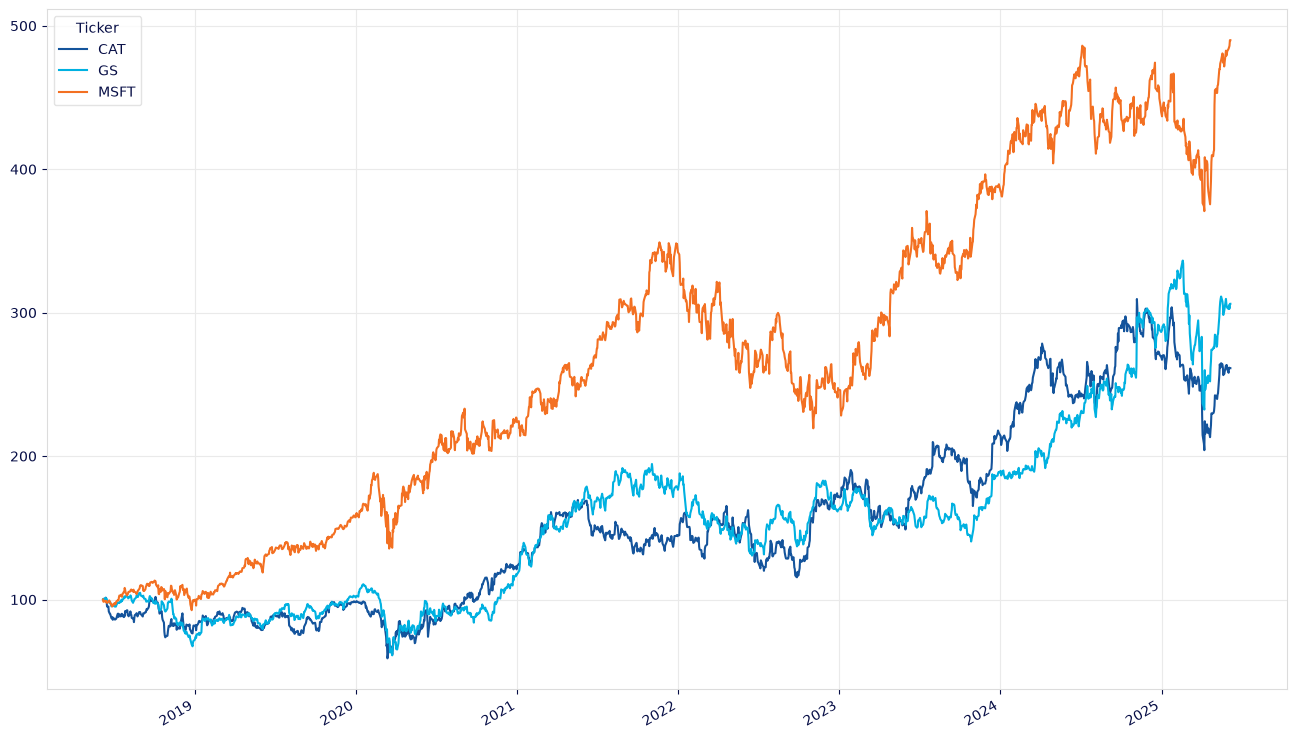

In [66]:
precios_norm = (df_filtrado / df_filtrado.iloc[0]) * 100

precios_norm.plot(figsize=(16,10))

#### Pasos a seguir

Analizar los componentes de la serie y tratarla como es debida para convertirla en estacionaria.

Si estacionalidad -> descomposición estacional
Si no estacionalidad -> tratar tendencia

Si tras tratar la serie existe heterocedasticidad -> Modelizar la volatilidad (ARCH o GARCH)

En caso de modelizar la volatilidad, se han mirado las autocorrelaciones y autocorrelaciones parciales sobre los rendimientos del activo al cuadrado. Sobre los resultados mostrados en las gráficas ACF y PACF se han decidido los parámetros con los que tratar de ajustar los ARCH y GARCH.


Para admitir un modelo, debe de cumplir con los siguientes puntos:
- Parámetros de modelo significativos
- El residuo post-modelo es homocedástico (ya no queda volatilidad)

In [67]:
def test_estacionariedad_y_het(series, lags=None):
    series = series.dropna()
    
    resultados = {}
    
    # 1. ADF
    adf_stat, adf_p, _, _, _, _ = adfuller(series, autolag='AIC')
    resultados['ADF'] = {
        'Estadístico': adf_stat,
        'p-value': adf_p,
        'Estacionariedad (0.05)': adf_p < 0.05
    }
    
    # 2. KPSS 
    kpss_stat, kpss_p, _, _ = kpss(series, regression='c', nlags='auto')
    resultados['KPSS'] = {
        'Estadístico': kpss_stat,
        'p-value': kpss_p,
        'Estacionariedad (0.05)': kpss_p > 0.05
    }
    
    # 3. ARCH
    arch_stat, arch_p, _, _ = het_arch(series, nlags=lags)
    resultados['ARCH_Heteroskedasticity'] = {
        'Estadístico': arch_stat,
        'p-value': arch_p,
        'Estacionariedad (0.05)': arch_p < 0.05
    }
    
    return pd.DataFrame(resultados).T

In [68]:
def evaluate_volatility_models(returns, max_arch_p=4):
    warnings.simplefilter('ignore', FutureWarning)
    results = []
    
    COL_MODEL = 'Modelo'
    COL_SIG = 'Todos los Parametros Significativos (<0.05)'
    COL_ARCH_P = 'ARCH-LM P-value'
    COL_HOMO = 'Homocedastica (>0.05)'
    COL_PVALS = 'P-values de los Parametros del Modelo'
    
    for p in range(1, max_arch_p + 1):
        model = arch_model(returns, vol='ARCH', p=p, rescale=False)
        res = model.fit(disp='off')
        
        pvals = res.pvalues
        all_sig = bool(all(pvals < 0.05))
        pvals_str = ", ".join([f"{idx}: {val:.4f}" for idx, val in pvals.items()])
        
        std_resid = res.std_resid.dropna()
        _, arch_lm_pval, _, _ = het_arch(std_resid, nlags=5)
        lm_passed = bool(arch_lm_pval > 0.05)
        
        results.append({
            COL_MODEL: f'ARCH({p})',
            COL_SIG: all_sig,
            COL_ARCH_P: round(arch_lm_pval, 4),
            COL_HOMO: lm_passed,
            COL_PVALS: pvals_str
        })
        
    garch_configs = [(1, 1), (1, 2), (2, 1), (2, 2)]
    for p, q in garch_configs:
        model = arch_model(returns, vol='GARCH', p=p, q=q, rescale=False, dist="normal", mean="Constant")
        res = model.fit(disp='off')
        
        pvals = res.pvalues
        all_sig = bool(all(pvals < 0.05))
        pvals_str = ", ".join([f"{idx}: {val:.4f}" for idx, val in pvals.items()])
        
        std_resid = res.std_resid.dropna()
        _, arch_lm_pval, _, _ = het_arch(std_resid, nlags=5)
        lm_passed = bool(arch_lm_pval > 0.05)
        
        results.append({
            COL_MODEL: f'GARCH({p},{q})',
            COL_SIG: all_sig,
            COL_ARCH_P: round(arch_lm_pval, 4),
            COL_HOMO: lm_passed,
            COL_PVALS: pvals_str
        })
        
    return pd.DataFrame(results)

## Tratamiento de las series temporales

### CAT (Caterpillar)

<Axes: >

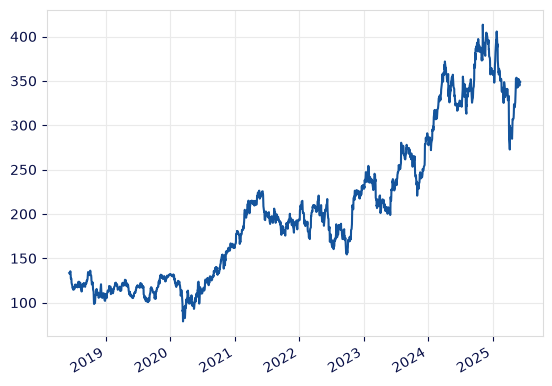

In [69]:
CAT.plot()

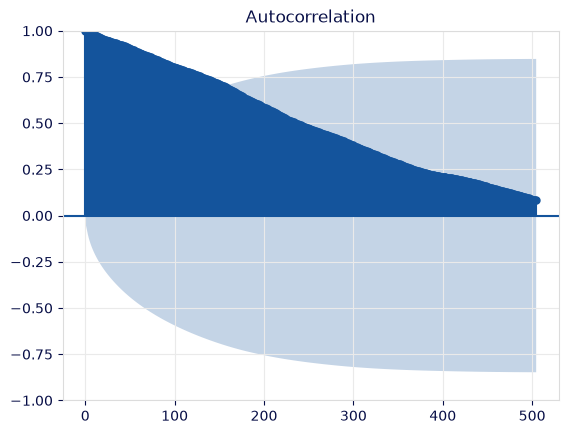

In [70]:
tsaplots.plot_acf(CAT, lags=504);

Al no descubrir ninguna estacionalidad, quitaremos solamente la tendencia y observaremos la homocedasticidad. Al tratarse de una serie financiera, y al poder diferenciar la serie para restarle la tendencia; se decide trabajar sobre los retornos. Los retornos o rentabilidades son un resultado similar a la diferenciación, además de ser el estándar del sector para tratar las series temporales, no sobre los precios absolutos.

In [71]:
CAT_r = CAT.pct_change().dropna()*100

<Axes: >

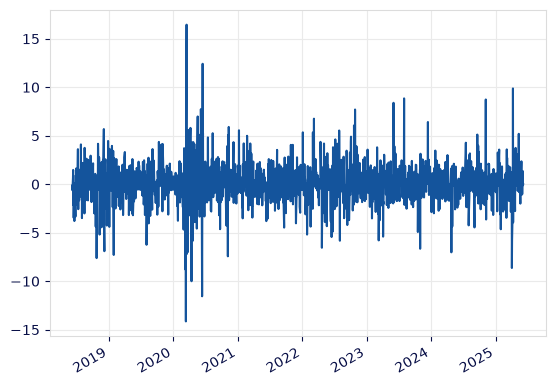

In [72]:
CAT_r.plot()

In [73]:
test_estacionariedad_y_het(CAT_r)

C:\Users\Markel\AppData\Local\Temp\ipykernel_484\3844326302.py:15: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_stat, kpss_p, _, _ = kpss(series, regression='c', nlags='auto')


,Estadístico,p-value,Estacionariedad (0.05)
ADF,-15.392905,0.0,True
KPSS,0.060526,0.1,True
ARCH_Heteroskedasticity,234.741986,0.0,True


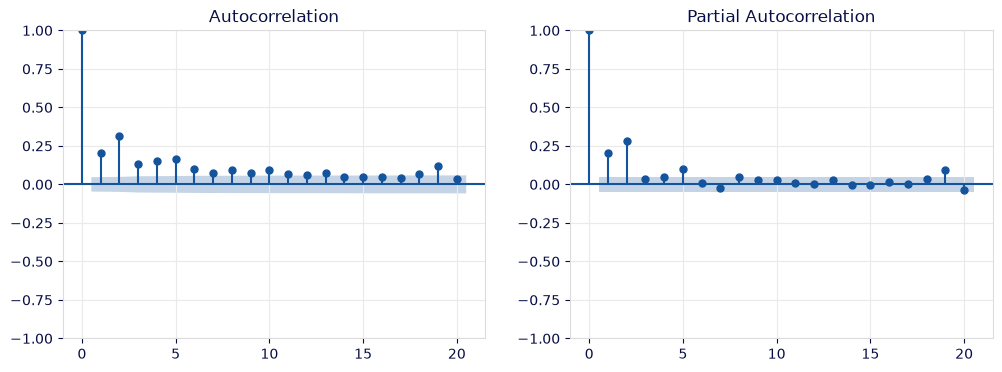

In [74]:
CAT_sq = CAT_r ** 2

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
tsaplots.plot_acf(CAT_sq, lags=20, ax=ax[0])
tsaplots.plot_pacf(CAT_sq, lags=20, ax=ax[1])
plt.show()

In [75]:
tabla_resumen = evaluate_volatility_models(CAT_r, max_arch_p=2)
print(tabla_resumen.to_string(index=False))

    Modelo  Todos los Parametros Significativos (<0.05)  ARCH-LM P-value  Homocedastica (>0.05)                                                           P-values de los Parametros del Modelo
   ARCH(1)                                        False           0.0000                  False                                                     mu: 0.5910, omega: 0.0000, alpha[1]: 0.0045
   ARCH(2)                                        False           0.0000                  False                                   mu: 0.1569, omega: 0.0000, alpha[1]: 0.0009, alpha[2]: 0.0012
GARCH(1,1)                                        False           0.5888                   True                                    mu: 0.0983, omega: 0.0053, alpha[1]: 0.0008, beta[1]: 0.0000
GARCH(1,2)                                        False           0.5813                   True                   mu: 0.1040, omega: 0.0060, alpha[1]: 0.0016, beta[1]: 0.0176, beta[2]: 0.6621
GARCH(2,1)                              

Gráficos para informe:

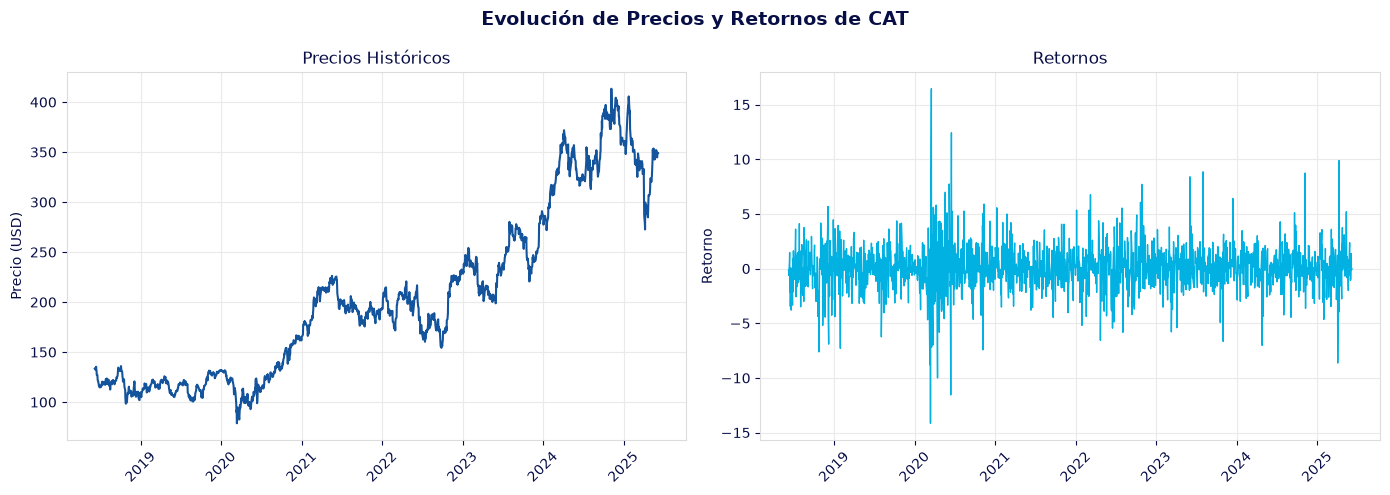

In [96]:
fig1, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
fig1.suptitle("Evolución de Precios y Retornos de CAT", fontsize=14, fontweight='bold')

ax1.plot(CAT.index, CAT.values, color=paleta_bbva["azul_logotipo"], linewidth=1.5)
ax1.set_title("Precios Históricos")
ax1.set_ylabel("Precio (USD)")
ax1.tick_params(axis='x', rotation=45)

ax2.plot(CAT_r.index, CAT_r.values, color=paleta_bbva["azul_celeste_aqua"], linewidth=1)
ax2.set_title("Retornos")
ax2.set_ylabel("Retorno")
ax2.tick_params(axis='x', rotation=45)

plt.tight_layout()

plt.savefig("../DATOS/GRAFICOS/figura_series_CAT.png", dpi=300, bbox_inches='tight')

plt.show()

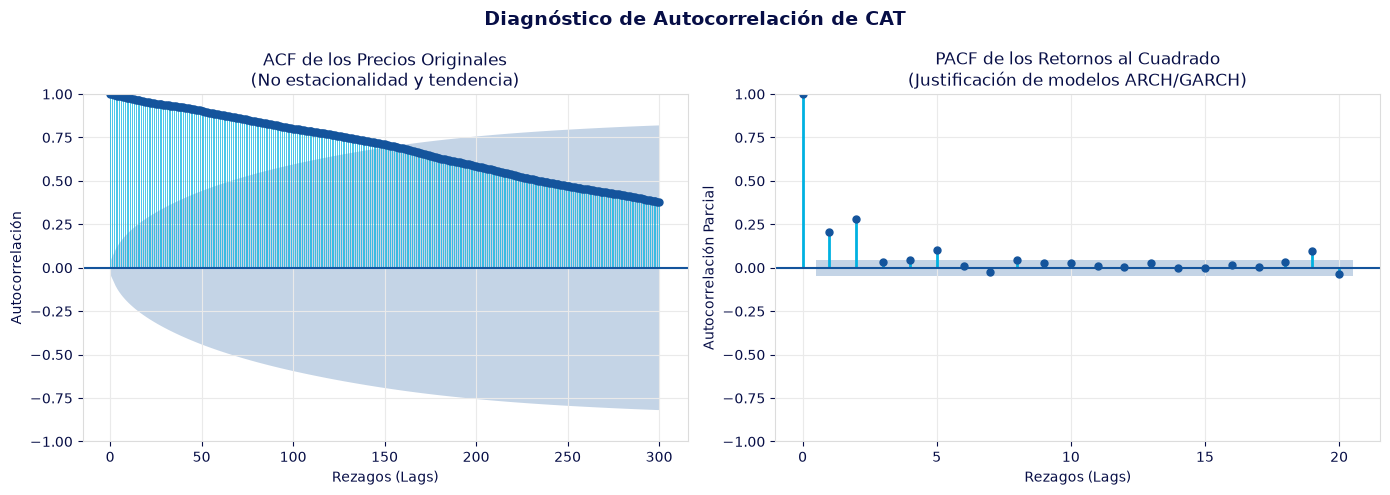

In [97]:
fig2, (ax_acf, ax_pacf) = plt.subplots(1, 2, figsize=(14, 5))
fig2.suptitle("Diagnóstico de Autocorrelación de CAT", fontsize=14, fontweight='bold')

tsaplots.plot_acf(CAT, lags=300, ax=ax_acf,
                  color=paleta_bbva["azul_logotipo"], 
                  vlines_kwargs={"colors": paleta_bbva["azul_celeste_aqua"], "linewidth": 0.5})
ax_acf.set_title("ACF de los Precios Originales\n(No estacionalidad y tendencia)")
ax_acf.set_xlabel("Rezagos (Lags)")
ax_acf.set_ylabel("Autocorrelación")

tsaplots.plot_pacf(CAT_sq, lags=20, ax=ax_pacf, 
                   color=paleta_bbva["azul_logotipo"], 
                   vlines_kwargs={"colors": paleta_bbva["azul_celeste_aqua"], "linewidth": 2})
ax_pacf.set_title("PACF de los Retornos al Cuadrado\n(Justificación de modelos ARCH/GARCH)")
ax_pacf.set_xlabel("Rezagos (Lags)")
ax_pacf.set_ylabel("Autocorrelación Parcial")

for ax in [ax_acf, ax_pacf]:
    for poly in ax.collections:
        if type(poly).__name__ == 'PolyCollection':
            poly.set_facecolor(paleta_bbva["azul_celeste_aqua"])
            poly.set_alpha(0.15)

plt.tight_layout()

plt.savefig("../DATOS/GRAFICOS/figura_autocorr_CAT.png", dpi=300, bbox_inches='tight')


plt.show()

### GS (Goldman Sachs)

<Axes: >

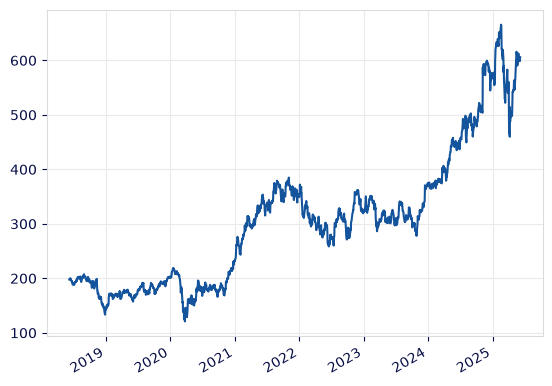

In [78]:
GS.plot()

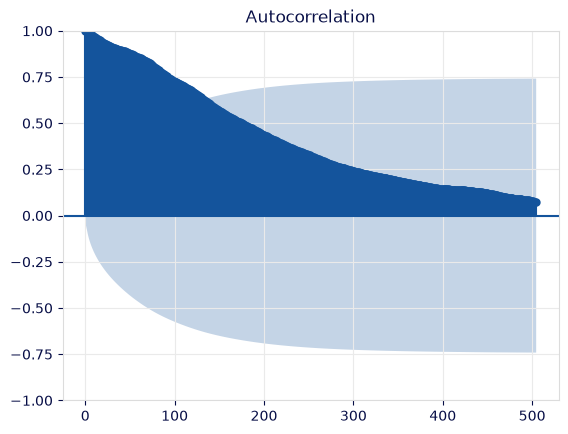

In [79]:
tsaplots.plot_acf(GS, lags=504);

Al no descubrir ninguna estacionalidad, quitaremos solamente la tendencia y observaremos la homocedasticidad. Al tratarse de una serie financiera, y al poder diferenciar la serie para restarle la tendencia; se decide trabajar sobre los retornos. Los retornos o rentabilidades son un resultado similar a la diferenciación, además de ser el estándar del sector para tratar las series temporales, no sobre los precios absolutos.

In [80]:
GS_r = GS.pct_change().dropna()*100

<Axes: >

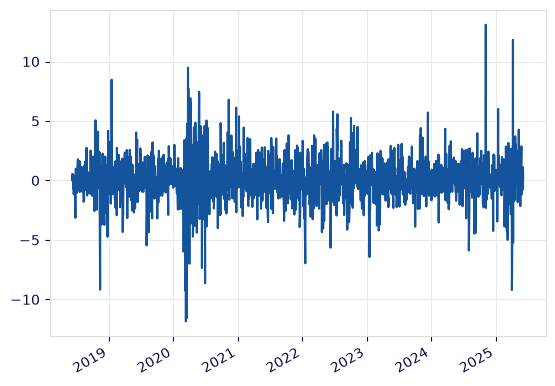

In [81]:
GS_r.plot()

In [82]:
test_estacionariedad_y_het(GS_r)

C:\Users\Markel\AppData\Local\Temp\ipykernel_484\3844326302.py:15: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_stat, kpss_p, _, _ = kpss(series, regression='c', nlags='auto')


,Estadístico,p-value,Estacionariedad (0.05)
ADF,-40.299486,0.0,True
KPSS,0.102191,0.1,True
ARCH_Heteroskedasticity,202.798468,0.0,True


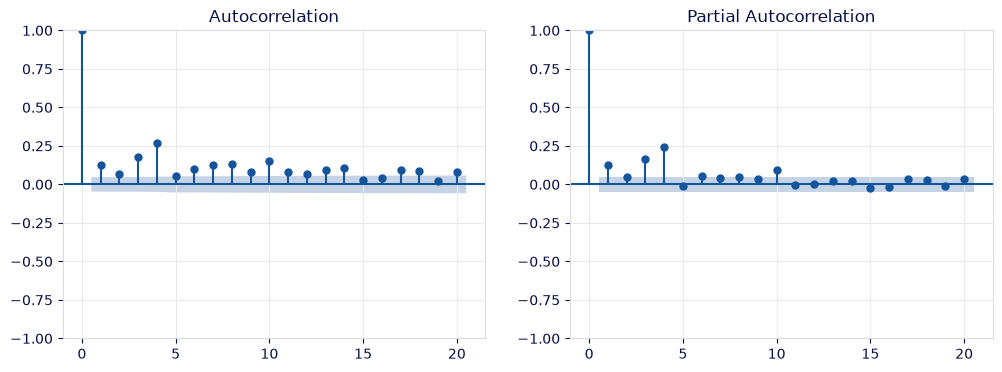

In [83]:
GS_sq = GS_r ** 2

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
tsaplots.plot_acf(GS_sq, lags=20, ax=ax[0])
tsaplots.plot_pacf(GS_sq, lags=20, ax=ax[1])
plt.show()

In [84]:
tabla_resumen = evaluate_volatility_models(GS_r, max_arch_p=4)
print(tabla_resumen.to_string(index=False))

    Modelo  Todos los Parametros Significativos (<0.05)  ARCH-LM P-value  Homocedastica (>0.05)                                                             P-values de los Parametros del Modelo
   ARCH(1)                                         True           0.0000                  False                                                       mu: 0.0185, omega: 0.0000, alpha[1]: 0.0016
   ARCH(2)                                         True           0.0000                  False                                     mu: 0.0232, omega: 0.0000, alpha[1]: 0.0034, alpha[2]: 0.0479
   ARCH(3)                                        False           0.0009                  False                   mu: 0.0079, omega: 0.0000, alpha[1]: 0.0021, alpha[2]: 0.1642, alpha[3]: 0.0025
   ARCH(4)                                        False           0.9334                   True mu: 0.0135, omega: 0.0000, alpha[1]: 0.0062, alpha[2]: 0.1533, alpha[3]: 0.0108, alpha[4]: 0.0018
GARCH(1,1)                    

Gráficos para informe:

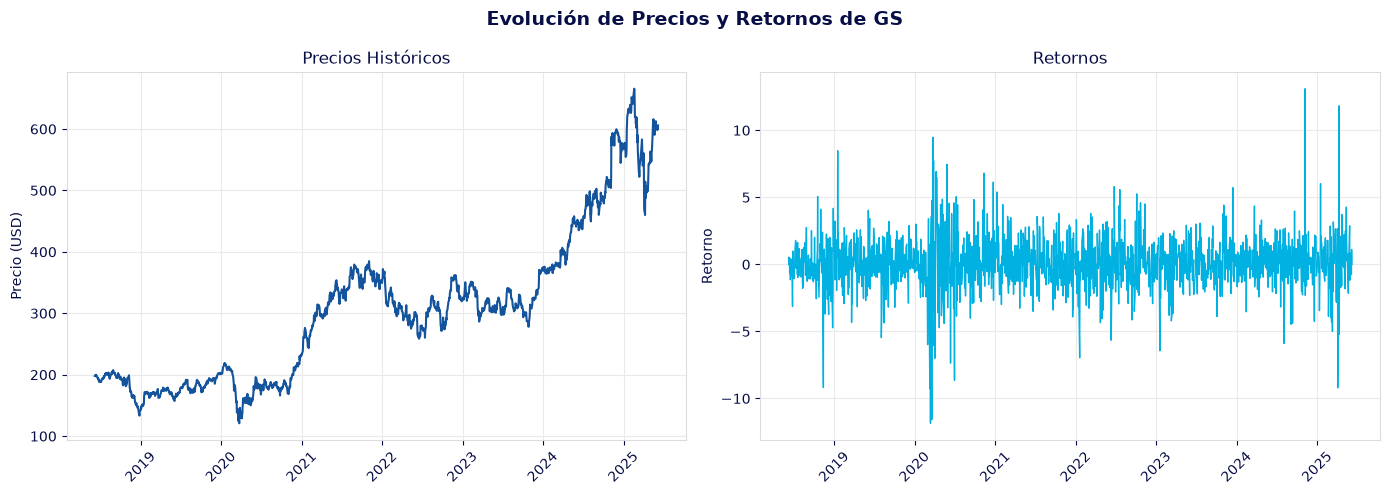

In [98]:
fig1, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
fig1.suptitle("Evolución de Precios y Retornos de GS", fontsize=14, fontweight='bold')

ax1.plot(GS.index, GS.values, color=paleta_bbva["azul_logotipo"], linewidth=1.5)
ax1.set_title("Precios Históricos")
ax1.set_ylabel("Precio (USD)")
ax1.tick_params(axis='x', rotation=45)

ax2.plot(GS_r.index, GS_r.values, color=paleta_bbva["azul_celeste_aqua"], linewidth=1)
ax2.set_title("Retornos")
ax2.set_ylabel("Retorno")
ax2.tick_params(axis='x', rotation=45)

plt.tight_layout()

plt.savefig("../DATOS/GRAFICOS/figura_series_GS.png", dpi=300, bbox_inches='tight')

plt.show()

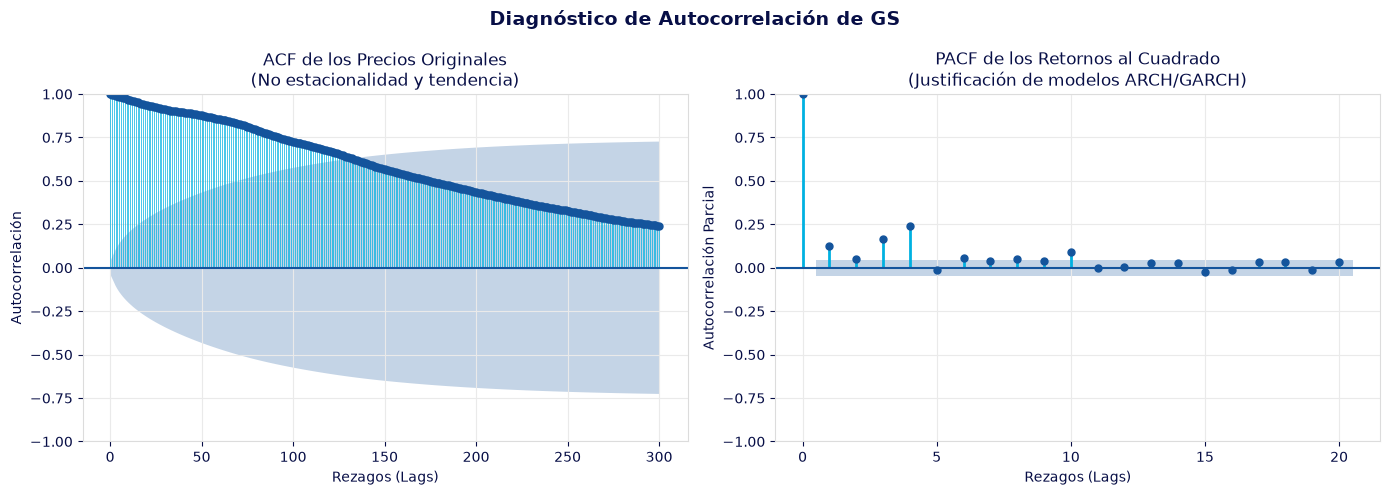

In [99]:
fig2, (ax_acf, ax_pacf) = plt.subplots(1, 2, figsize=(14, 5))
fig2.suptitle("Diagnóstico de Autocorrelación de GS", fontsize=14, fontweight='bold')

tsaplots.plot_acf(GS, lags=300, ax=ax_acf,
                  color=paleta_bbva["azul_logotipo"], 
                  vlines_kwargs={"colors": paleta_bbva["azul_celeste_aqua"], "linewidth": 0.5})
ax_acf.set_title("ACF de los Precios Originales\n(No estacionalidad y tendencia)")
ax_acf.set_xlabel("Rezagos (Lags)")
ax_acf.set_ylabel("Autocorrelación")

tsaplots.plot_pacf(GS_sq, lags=20, ax=ax_pacf, 
                   color=paleta_bbva["azul_logotipo"], 
                   vlines_kwargs={"colors": paleta_bbva["azul_celeste_aqua"], "linewidth": 2})
ax_pacf.set_title("PACF de los Retornos al Cuadrado\n(Justificación de modelos ARCH/GARCH)")
ax_pacf.set_xlabel("Rezagos (Lags)")
ax_pacf.set_ylabel("Autocorrelación Parcial")

for ax in [ax_acf, ax_pacf]:
    for poly in ax.collections:
        if type(poly).__name__ == 'PolyCollection':
            poly.set_facecolor(paleta_bbva["azul_celeste_aqua"])
            poly.set_alpha(0.15)

plt.tight_layout()

plt.savefig("../DATOS/GRAFICOS/figura_autocorr_GS.png", dpi=300, bbox_inches='tight')

plt.show()

### MSFT (Microsoft)

<Axes: >

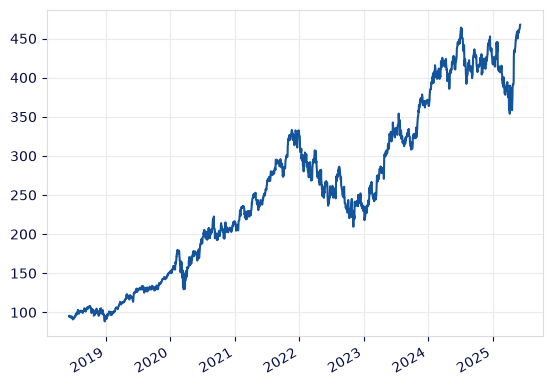

In [87]:
MSFT.plot()

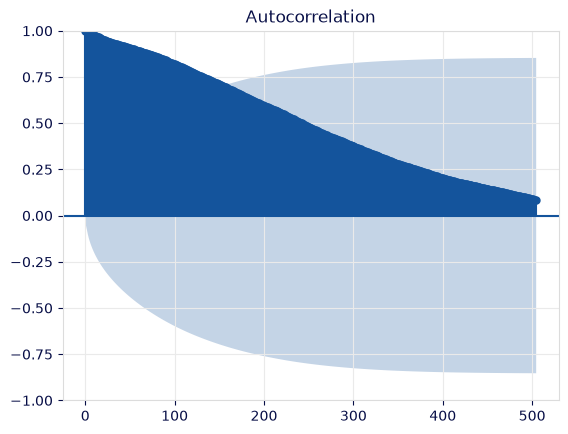

In [88]:
tsaplots.plot_acf(MSFT, lags=504);

Al no descubrir ninguna estacionalidad, quitaremos solamente la tendencia y observaremos la homocedasticidad. Al tratarse de una serie financiera, y al poder diferenciar la serie para restarle la tendencia; se decide trabajar sobre los retornos. Los retornos o rentabilidades son un resultado similar a la diferenciación, además de ser el estándar del sector para tratar las series temporales, no sobre los precios absolutos.

In [89]:
MSFT_r = MSFT.pct_change().dropna()*100

<Axes: >

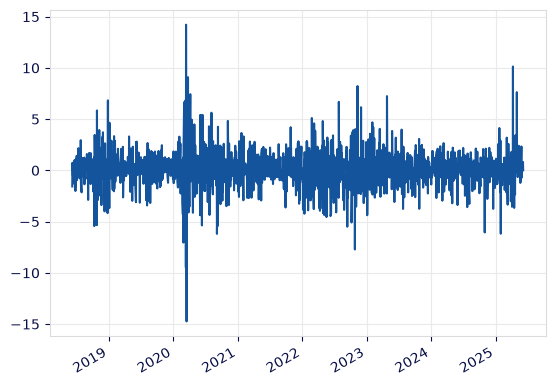

In [90]:
MSFT_r.plot()

In [91]:
test_estacionariedad_y_het(MSFT_r)

C:\Users\Markel\AppData\Local\Temp\ipykernel_484\3844326302.py:15: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_stat, kpss_p, _, _ = kpss(series, regression='c', nlags='auto')


,Estadístico,p-value,Estacionariedad (0.05)
ADF,-13.402208,0.0,True
KPSS,0.084616,0.1,True
ARCH_Heteroskedasticity,459.757458,0.0,True


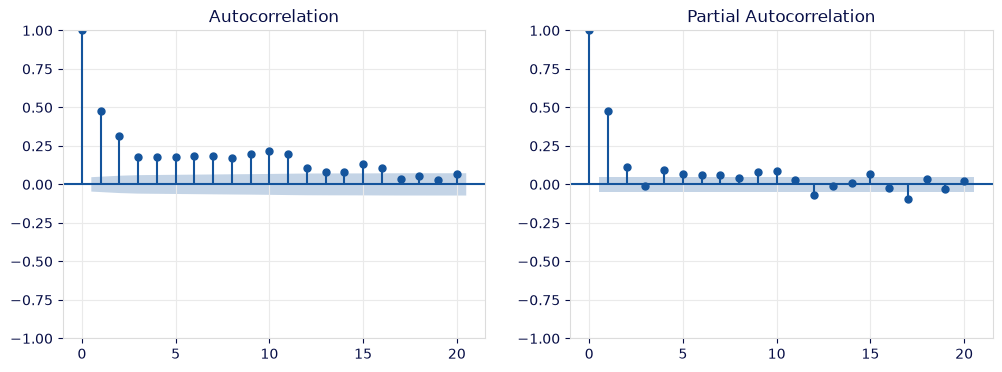

In [92]:
MSFT_sq = MSFT_r ** 2

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
tsaplots.plot_acf(MSFT_sq, lags=20, ax=ax[0])
tsaplots.plot_pacf(MSFT_sq, lags=20, ax=ax[1])
plt.show()

In [93]:
tabla_resumen = evaluate_volatility_models(MSFT_r, max_arch_p=2)
print(tabla_resumen.to_string(index=False))

    Modelo  Todos los Parametros Significativos (<0.05)  ARCH-LM P-value  Homocedastica (>0.05)                                                           P-values de los Parametros del Modelo
   ARCH(1)                                         True           0.0000                  False                                                     mu: 0.0003, omega: 0.0000, alpha[1]: 0.0000
   ARCH(2)                                         True           0.0030                  False                                   mu: 0.0011, omega: 0.0000, alpha[1]: 0.0001, alpha[2]: 0.0002
GARCH(1,1)                                        False           0.9127                   True                                    mu: 0.0004, omega: 0.0600, alpha[1]: 0.0005, beta[1]: 0.0000
GARCH(1,2)                                        False           0.9142                   True                   mu: 0.0004, omega: 0.0592, alpha[1]: 0.0044, beta[1]: 0.0948, beta[2]: 0.6563
GARCH(2,1)                              

Gráficos para informe:

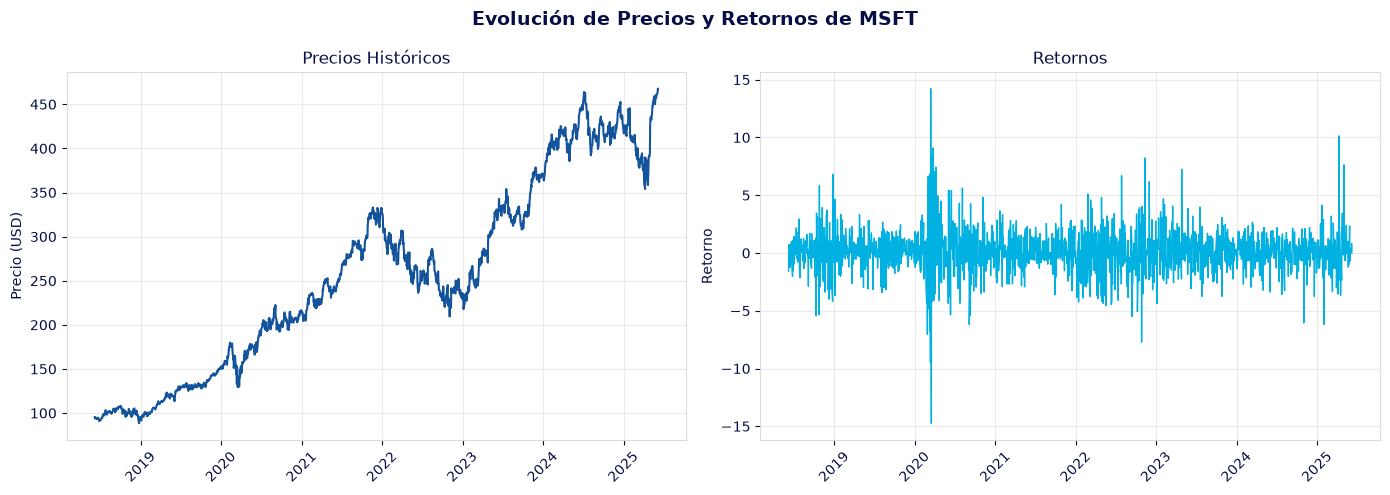

In [100]:
fig1, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
fig1.suptitle("Evolución de Precios y Retornos de MSFT", fontsize=14, fontweight='bold')

ax1.plot(MSFT.index, MSFT.values, color=paleta_bbva["azul_logotipo"], linewidth=1.5)
ax1.set_title("Precios Históricos")
ax1.set_ylabel("Precio (USD)")
ax1.tick_params(axis='x', rotation=45)

ax2.plot(MSFT_r.index, MSFT_r.values, color=paleta_bbva["azul_celeste_aqua"], linewidth=1)
ax2.set_title("Retornos")
ax2.set_ylabel("Retorno")
ax2.tick_params(axis='x', rotation=45)

plt.tight_layout()

plt.savefig("../DATOS/GRAFICOS/figura_series_MSFT.png", dpi=300, bbox_inches='tight')

plt.show()

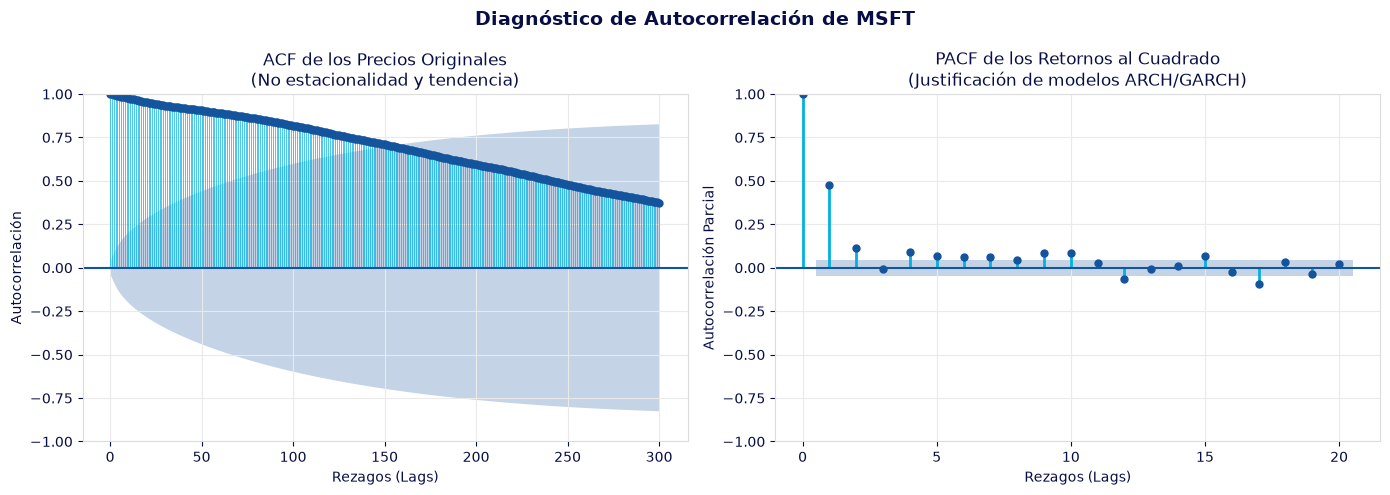

In [101]:
fig2, (ax_acf, ax_pacf) = plt.subplots(1, 2, figsize=(14, 5))
fig2.suptitle("Diagnóstico de Autocorrelación de MSFT", fontsize=14, fontweight='bold')

tsaplots.plot_acf(MSFT, lags=300, ax=ax_acf,
                  color=paleta_bbva["azul_logotipo"], 
                  vlines_kwargs={"colors": paleta_bbva["azul_celeste_aqua"], "linewidth": 0.5})
ax_acf.set_title("ACF de los Precios Originales\n(No estacionalidad y tendencia)")
ax_acf.set_xlabel("Rezagos (Lags)")
ax_acf.set_ylabel("Autocorrelación")

tsaplots.plot_pacf(MSFT_sq, lags=20, ax=ax_pacf, 
                   color=paleta_bbva["azul_logotipo"], 
                   vlines_kwargs={"colors": paleta_bbva["azul_celeste_aqua"], "linewidth": 2})
ax_pacf.set_title("PACF de los Retornos al Cuadrado\n(Justificación de modelos ARCH/GARCH)")
ax_pacf.set_xlabel("Rezagos (Lags)")
ax_pacf.set_ylabel("Autocorrelación Parcial")

for ax in [ax_acf, ax_pacf]:
    for poly in ax.collections:
        if type(poly).__name__ == 'PolyCollection':
            poly.set_facecolor(paleta_bbva["azul_celeste_aqua"])
            poly.set_alpha(0.15)

plt.tight_layout()

plt.savefig("../DATOS/GRAFICOS/figura_autocorr_MSFT.png", dpi=300, bbox_inches='tight')

plt.show()